In [2]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

In [3]:
P_in = 6e5
P_out = 5.45e5
print(P_in/2+P_out/2)

572500.0


In [ ]:
# Fluid properties (from Table 3.1 and text)
gamma = 1.41  # Approximate gamma = cp / cv
R = 287  # J/kg·K (adjusted to standard air for simplicity; thesis uses ~306)
cp = 1050  # J/kg·K
cv = 744  # J/kg·K

# Pressures (Pa)
P_in = 6e5
P_out = 5.45e5
P0 = (P_in+P_out)/2*1.01 # Initial average pressure

# Temperatures (K)
T_in = 300
T0 = T_in

# Resonator geometry
A_neck = 2.85e-4  # m²
L_neck = 0.15  # m
m_gas = 0.00015  # kg
V0_cv = 5.91e-5  # m³ (calculated from k_cv)
V0_pass = 3.93e-4  # m³ (calculated from k_passive)

# Damping from Q = 60
f = 130  # Hz
omega = 2 * np.pi * f
Q = 60
b_gas = omega * m_gas / Q

# Reed parameters (for zeta = 0.6 example)
zeta = 0.6
dP = P_in - P_out
dP_max = dP / (2 * zeta)  # Symmetric inlet/outlet
m_max = 0.001  # kg/s (adjust this to match amplitude; thesis implies ~0.001 for m_avg ~0.00037)

# Time span
t_span = (0, 1)  # s (adjust for more cycles)
t_eval = np.linspace(*t_span, 10000000)  # High resolution

# Initial conditions
x0 = 0.0 * L_neck  # Small disturbance
v0 = 10
M0_cv = P0 * V0_cv / (R * T0)
E0_cv = cv * M0_cv * T0
y0 = [x0, v0, M0_cv, E0_cv]

In [5]:
def reed_flow(dP, m_max, dP_max):
    """Mass flow rate through reed valve (positive for flow from high to low pressure)."""
    u = dP / dP_max
    if dP > 0 and dP < dP_max:
        return m_max * (1 - u) * np.sqrt(u)
    elif dP <= 0:
        return - m_max * (1 - u) * np.sqrt(np.abs(u))
    else:
        return 0.0

In [6]:
def acoustic_expander_ode(t, y):
    x, v, M_cv, E_cv = y

    V_cv = V0_cv + x * A_neck
    T_cv = E_cv / (cv * M_cv) if M_cv > 0 else T0
    P_cv = M_cv * R * T_cv / V_cv

    V_pass = V0_pass - x * A_neck
    P_pass = P0 * (V0_pass / V_pass)**gamma if V_pass > 0 else P0

    dP_in = P_in - P_cv
    dP_out = P_cv - P_out

    m_in = reed_flow(dP_in,m_max,dP_max)
    m_out = reed_flow(dP_out,m_max,dP_max)

    dV_cv_dt = A_neck * v
    dM_dt = m_in - m_out
    dE_dt = -P_cv * dV_cv_dt + m_in * cp * T_in - m_out * cp * T_cv

    dx_dt = v
    dv_dt = (P_cv - P_pass) * A_neck / m_gas - (b_gas / m_gas) * v

    return [dx_dt, dv_dt, dM_dt, dE_dt]

In [7]:
sol = solve_ivp(acoustic_expander_ode, t_span, y0, t_eval=t_eval, method='RK45', rtol=1e-6, atol=1e-8)

# Extract results
t = sol.t
x = sol.y[0]
v = sol.y[1]
M_cv = sol.y[2]
E_cv = sol.y[3]

V_cv = V0_cv + x * A_neck
T_cv = E_cv / (cv * M_cv)
P_cv = M_cv * R * T_cv / V_cv


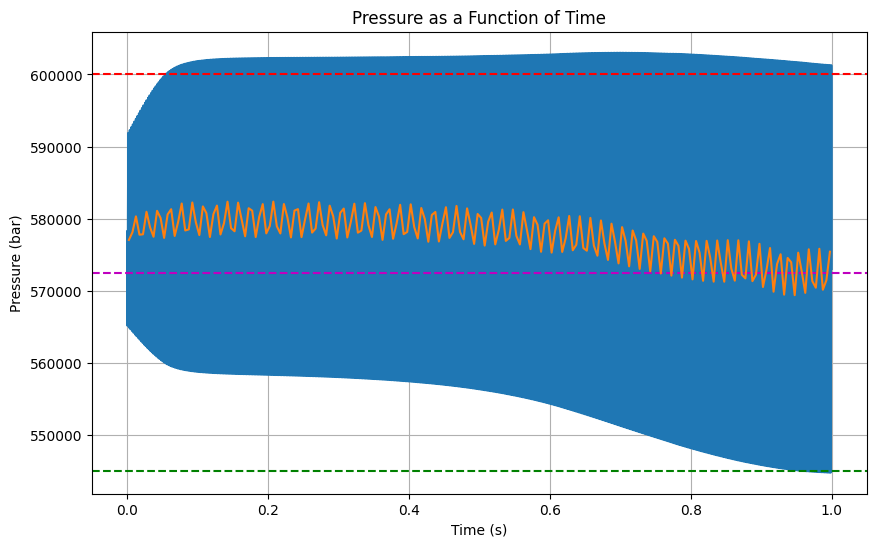

In [70]:
n_average = 500 # number of points we are averaging out

plt.figure(figsize=(10, 6))
plt.plot(t, P_cv, label='Control Volume Pressure (bar)')
plt.axhline(P_in, color='r', linestyle='--', label='Inlet Pressure')
plt.axhline(P_out, color='g', linestyle='--', label='Outlet Pressure')
plt.axhline((P_out+P_in)/2, color='m', linestyle='--', label='Average Pressure')

plt.plot(np.mean(t.reshape(-1, n_average), axis=1), np.mean(P_cv.reshape(-1, n_average), axis=1),label='average')
plt.xlabel('Time (s)')
plt.ylabel('Pressure (bar)')
plt.title('Pressure as a Function of Time')
#plt.legend()
plt.grid(True)
plt.savefig(f"Pressure_Oscillation_P_0={P0:.1f}__v0={v0:.2f}__f={f}.pdf")
plt.show()


In [71]:
np.savez_compressed("run_success.npz", t=t, v=v, P_cv=P_cv)

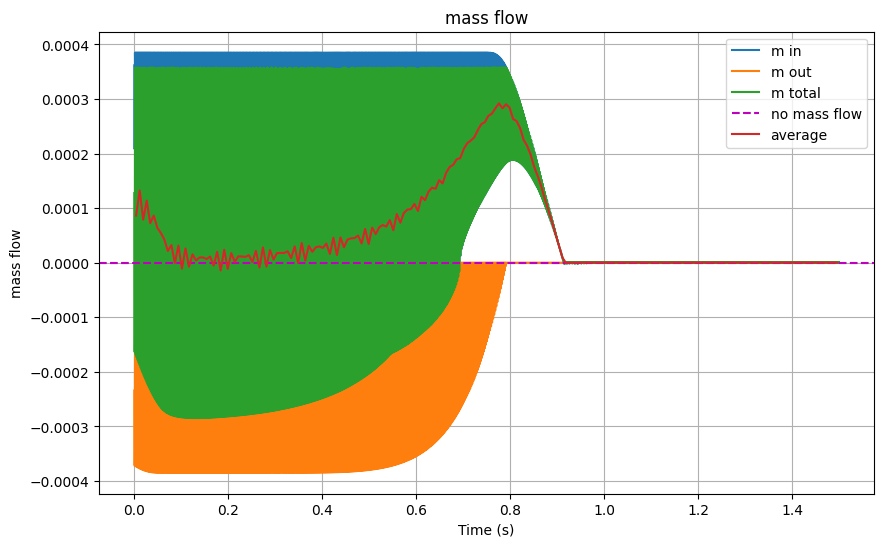

In [57]:
n_average = 500 # number of points we are averaging out

m_in = np.zeros_like(P_cv)
m_out = np.zeros_like(P_cv)
for i in range(len(P_cv)):
  dP_in = P_in - P_cv[i]
  dP_out = P_cv[i] - P_out
  m_in[i] = reed_flow(dP_in,m_max,dP_max)
  m_out[i] = -reed_flow(dP_out,m_max,dP_max)

plt.figure(figsize=(10, 6))
plt.plot(t,m_in, label='m in')
plt.plot(t,m_out, label = 'm out')
plt.plot(t,m_in + m_out, label='m total')
plt.axhline(0.0, color='m', linestyle='--', label='no mass flow')

plt.plot(np.mean(t.reshape(-1, n_average), axis=1), np.mean((m_in + m_out).reshape(-1, n_average), axis=1),label='average')
plt.xlabel('Time (s)')
plt.ylabel('mass flow')
plt.title('mass flow')
plt.legend()
plt.grid(True)
plt.savefig(f"MassFlows_P_0={P0:.1f}__v0={v0:.2f}__f={f}.pdf")
plt.show()

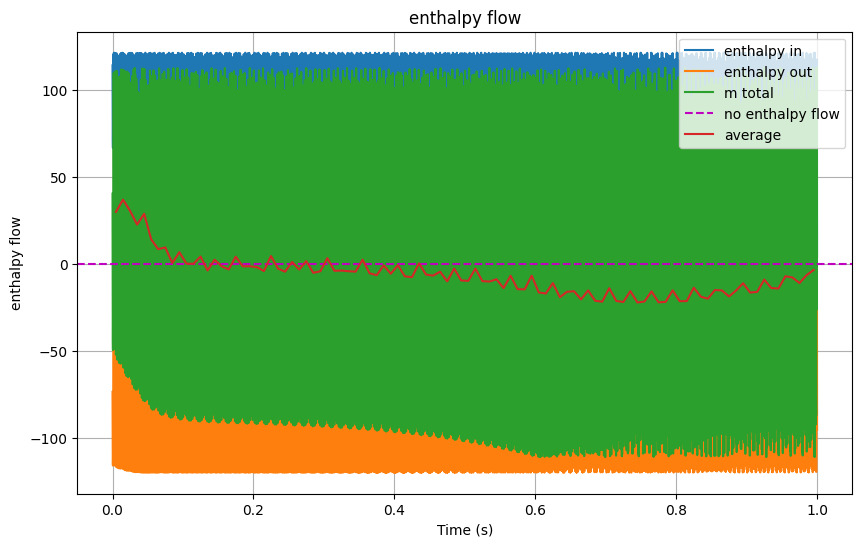

In [ ]:
#enthalpy flow
n_average = 50 # number of points we are averaging out

enthalpy_in = m_in * T_in * cp
enthalpy_out = m_out*T_cv*cp
plt.figure(figsize=(10, 6))

plt.plot(t,enthalpy_in, label='enthalpy in')
plt.plot(t,enthalpy_out, label = 'enthalpy out')
plt.plot(t,enthalpy_out + enthalpy_in, label='m total')
plt.axhline(0.0, color='m', linestyle='--', label='no enthalpy flow')

plt.plot(np.mean(t.reshape(-1, n_average), axis=1), np.mean((enthalpy_out + enthalpy_in).reshape(-1, n_average), axis=1),label='average')
plt.xlabel('Time (s)')
plt.ylabel('enthalpy flow')
plt.title('enthalpy flow')
plt.legend()
plt.grid(True)
plt.savefig(f"Enthalpy_P_0={P0:.1f}__v0={v0:.2f}__f={f}.pdf")
plt.show()

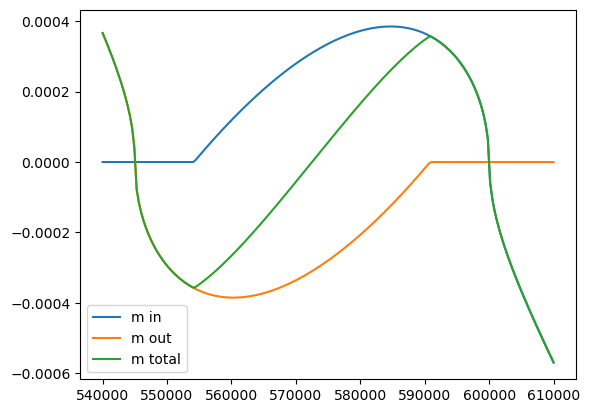

In [8]:
# '''Plot Reed Flow Curve'''
P_cv = np.linspace(5.4e5,6.1e5,200)
m_in = np.zeros_like(P_cv)
m_out = np.zeros_like(P_cv)
for i in range(len(P_cv)):
  dP_in = P_in - P_cv[i]
  dP_out = P_cv[i] - P_out
  m_in[i] = reed_flow(dP_in,m_max,dP_max)
  m_out[i] = -reed_flow(dP_out,m_max,dP_max)
plt.plot(P_cv,m_in,label='m in')
plt.plot(P_cv,m_out, label = 'm out')
plt.plot(P_cv,m_in + m_out, label='m total')
plt.legend()
plt.show()

In [ ]:
# =========================
# >>> Heat map: P0 vs v0 <<<
# =========================
# Drop this block after your existing code. It only *uses* the global parameters and
# the functions you already defined (reed_flow, acoustic_expander_ode).

# ================================
# >>> Parallel heatmap (joblib) <<<
# ================================
# Requirements in Colab (uncomment once):
# !pip -q install joblib

import os
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed


def _amplitude_half_pp(P_series, t_series, tail_window=0.1):
    """Half peak-to-peak amplitude over the last `tail_window` seconds."""
    if t_series.size < 5:
        return np.nan
    t_end = t_series[-1]
    mask = t_series >= (t_end - tail_window)
    if not np.any(mask):
        mask = slice(-max(10, t_series.size // 10), None)
    seg = P_series[mask]
    if seg.size < 3:
        return np.nan
    return 0.5 * (np.nanmax(seg) - np.nanmin(seg))

def simulate_once(P0_val, v0_val, t_span=(0.0, 1.0), n_eval=5000):
    """
    Run one simulation for given initial mean pressure P0_val (Pa)
    and initial velocity v0_val (m/s). Returns amplitude (Pa).
    Notes:
      - Uses your globals (P_in, P_out, R, cp, cv, A_neck, V0_cv, V0_pass, m_gas, b_gas, etc.).
      - P_pass uses P0_val via the global P0 inside acoustic_expander_ode, so we
        temporarily set the module-global P0 to P0_val for this call.
    """
    global P0  # so acoustic_expander_ode sees it in P_pass
    P0_backup = P0
    try:
        P0 = float(P0_val)

        # Initial state consistent with P0_val and T0
        M0_cv = P0 * V0_cv / (R * T0)
        E0_cv = cv * M0_cv * T0
        x0 = 0.0
        y0 = [x0, float(v0_val), M0_cv, E0_cv]

        t_eval_local = np.linspace(t_span[0], t_span[1], n_eval)
        sol = solve_ivp(
            acoustic_expander_ode, t_span, y0,
            t_eval=t_eval_local, method='RK45', rtol=1e-6, atol=1e-8
        )
        t = sol.t
        x = sol.y[0]
        M_cv = sol.y[2]
        E_cv = sol.y[3]

        V_cv = V0_cv + x * A_neck
        T_cv = E_cv / (cv * M_cv)
        P_cv = M_cv * R * T_cv / V_cv

        return _amplitude_half_pp(P_cv, t, tail_window=0.1)  # Pa
    except Exception:
        return np.nan
    finally:
        P0 = P0_backup


def _amp_task(idx_v, idx_p, P0_val, v0_val, t_span, n_eval):
    """
    Small wrapper so joblib can run a single (P0, v0) evaluation in a child process.
    Relies on simulate_once(P0_val, v0_val, t_span, n_eval) being defined in this module.
    Returns (row_index, col_index, amplitude_Pa).
    """
    amp = simulate_once(P0_val, v0_val, t_span=t_span, n_eval=n_eval)  # <-- uses your function
    return idx_v, idx_p, amp

def plot_heatmap_P0_v0_parallel(
    P0_vals=None, v0_vals=None, t_span=(0.0, 1.0), n_eval=8000,
    n_jobs=-1, verbose=5, save_path="heatmap_P0_v0_parallel.pdf"
):
    """
    Parallel version of the P0–v0 sweep using joblib (process-based).
    - n_jobs: number of worker processes (-1 = all cores).
    - verbose: joblib progress verbosity (0..10). Try 5 for periodic updates.
    """
    # Defaults (reuse your module globals P0, etc.)
    if P0_vals is None:
        P0_vals = np.linspace(0.97 * P0, 1.03 * P0, 25)
    if v0_vals is None:
        v0_vals = np.linspace(-15.0, 15.0, 31)

    # Pre-allocate output
    heat = np.full((len(v0_vals), len(P0_vals)), np.nan, dtype=float)

    # Build task list (row-major so we can fill by indices returned from workers)
    tasks = []
    for i_v, v0_val in enumerate(v0_vals):
        for i_p, P0_val in enumerate(P0_vals):
            tasks.append((i_v, i_p, P0_val, v0_val, t_span, n_eval))

    # Limit BLAS/OpenMP oversubscription for child processes (speeds up solve_ivp)
    os.environ.setdefault("OMP_NUM_THREADS", "1")
    os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
    os.environ.setdefault("MKL_NUM_THREADS", "1")
    os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
    os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

    # Run in parallel
    results = Parallel(n_jobs=n_jobs, verbose=verbose, prefer="processes")(
        delayed(_amp_task)(i_v, i_p, P0_val, v0_val, t_span, n_eval)
        for (i_v, i_p, P0_val, v0_val, t_span, n_eval) in tasks
    )

    # Assemble the heat matrix
    for i_v, i_p, amp in results:
        heat[i_v, i_p] = amp

    # Plot
    fig, ax = plt.subplots(figsize=(8, 5.6))
    im = ax.imshow(
        heat,
        origin="lower",
        aspect="auto",
        extent=[P0_vals[0] / 1e5, P0_vals[-1] / 1e5, v0_vals[0], v0_vals[-1]],
    )
    ax.set_xlabel("Initial pressure $P_0$ [bar]")
    ax.set_ylabel("Initial velocity $v_0$ [m/s]")
    ax.set_title("Oscillation amplitude of $P_{cv}$ after 1 s (half peak-to-peak)")
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Amplitude [Pa]")
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()

    return heat, P0_vals, v0_vals



In [ ]:
if __name__ == "__main__":
    # Choose ranges (reuse your global P0)
    P0_range = np.linspace(0.97 * P0, 1.03 * P0, 50)   # adjust as needed
    v0_range = np.linspace(-15.0, 15.0, 50)

    p0_min_bar = P0_range.min() / 1e5
    p0_max_bar = P0_range.max() / 1e5
    v0_min     = v0_range.min()
    v0_max     = v0_range.max()

    save_path = (
        f"Oscillation_Plots/"
        f"heatmap_P0_v0_parallel_"
        f"P0[{p0_min_bar:.2f}-{p0_max_bar:.2f}]bar_"
        f"v0[{v0_min:.1f}-{v0_max:.1f}]ms_"
        f"{len(v0_range)}x{len(P0_range)}.pdf"
    )

    heat, P0_vals, v0_vals = plot_heatmap_P0_v0_parallel(
        P0_vals=P0_range,
        v0_vals=v0_range,
        t_span=(0.0, 1.0),
        n_eval=5000,
        n_jobs=-1,
        verbose=5,
        save_path=save_path,
    )

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.


KeyboardInterrupt: 

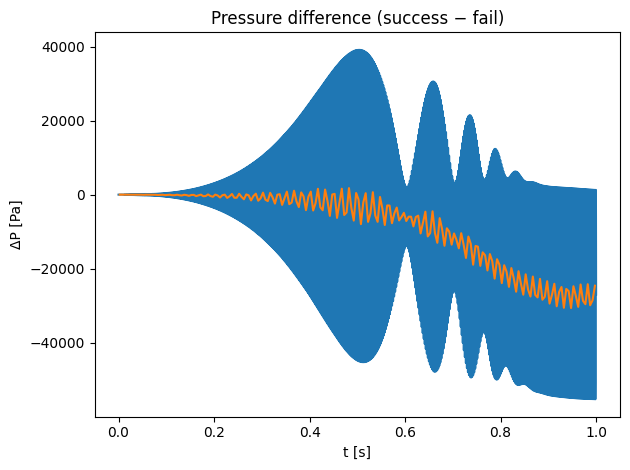

In [72]:
import os
# Later: load, align (if needed), and plot ΔP = P_B − P_A
success = np.load("run_success.npz")
fail = np.load("run_fail.npz")
n_average=500
t_success, P_success,v_success = success["t"], success["P_cv"], success["v"]
t_fail, P_fail, v_fail = fail["t"], fail["P_cv"], fail["v"]

# If tA and tB are identical (common case), just subtract:
# (If not identical, interpolate PB onto tA first.)
plt.figure()
plt.plot(t_success, P_success - P_fail)  # OK only if tA == tB
plt.plot(np.mean(t.reshape(-1, n_average), axis=1), np.mean((P_success - P_fail).reshape(-1, n_average), axis=1),label='average')

plt.xlabel("t [s]")
plt.ylabel("ΔP [Pa]")
plt.title("Pressure difference (success − fail)")
plt.tight_layout()
plt.show()

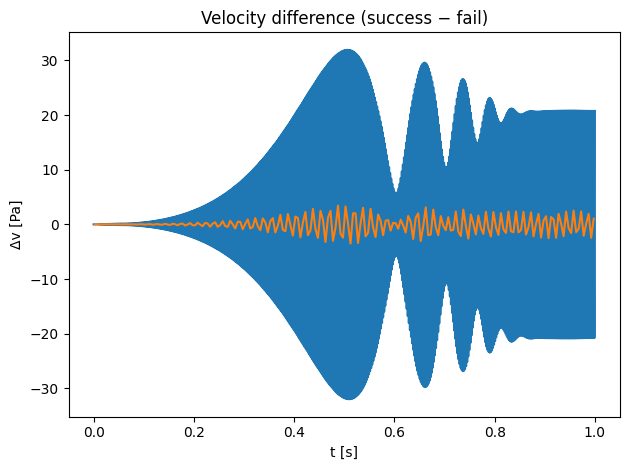

In [73]:
plt.plot(t_success, v_success - v_fail)  # OK only if tA == tB
plt.plot(np.mean(t.reshape(-1, n_average), axis=1), np.mean((v_success - v_fail).reshape(-1, n_average), axis=1),label='average')

plt.xlabel("t [s]")
plt.ylabel("Δv [Pa]")
plt.title("Velocity difference (success − fail)")
plt.tight_layout()
plt.show()